# 一键运行整个量化策略 Pipeline

**日常只需打开这个文件，点击 PyCharm 的 Run All（运行全部）。**

流程：读取本地 CSV → 复权 OHLC → RSI / SMA 与原策略信号 → 基线 → IS 网格 → 2020 OOS / Walk-forward → 2024 OOS → 9 月与 10 月模拟窗口。

数据和信号只准备一次，36 组参数的完整历史回测只计算一次；各阶段显式接收同一份结果。所有策略和回测计算沿用原项目。全流程不下载或覆盖数据。

Python 3.10+；首次使用请在 PyCharm 项目解释器环境安装 `pipeline/requirements.txt`。各文件必须一起保留在本目录，数据保留在 `../data/raw/etf_daily.csv`。工作目录可以是项目根目录或本目录。

所有输出保存在 `results` 字典，同时展示表格与图。不要只运行最后一格的全新内核：使用 Run All 即会先定义函数再调用主函数。


## 函数关系

```text
main()
├── prepare_context()：读取 CSV → 复权价格 → 生成信号
├── run_all()：一次计算 36 组参数的完整历史回测
└── run_stage()：依次调用各阶段 main()
    ├── evaluate_baseline() / plot_baseline()
    ├── evaluate_grid()
    ├── evaluate_frozen_parameters() / compare_oos() / evaluate_walkforward()
    ├── evaluate_2024() / compare_2024()
    ├── evaluate_september()
    └── evaluate_october()
```

这些小函数负责单个步骤，最后的 `main()` 负责把步骤串成完整流程。


In [1]:
from pathlib import Path
import os
import json

def find_pipeline_dir():
    """支持从项目根目录、pipeline 目录及项目内子目录启动。"""
    roots = ([Path(os.environ['ETF_PROJECT_ROOT']).expanduser()] if os.environ.get('ETF_PROJECT_ROOT') else [])
    roots += [Path.cwd(), *Path.cwd().parents]
    for root in roots:
        for candidate in (root / 'pipeline', root):
            if (candidate / '00_engine.ipynb').is_file() and (candidate / '07_run_pipeline.ipynb').is_file():
                return candidate.resolve()
    raise FileNotFoundError('找不到 pipeline 文件夹。请将 PyCharm 工作目录设为项目根目录，或设置 ETF_PROJECT_ROOT。')

PIPELINE_DIR = find_pipeline_dir()

def load_notebook_definitions(filename):
    """独立命名空间加载函数；不执行被加载 notebook 的入口单元格。"""
    path = PIPELINE_DIR / filename
    notebook = json.loads(path.read_text(encoding='utf-8'))
    namespace = {'__name__': 'pipeline_module'}
    for number, item in enumerate(notebook['cells']):
        if item['cell_type'] == 'code' and 'pipeline-entry' not in item.get('metadata', {}).get('tags', []):
            exec(compile(''.join(item['source']), f'{path}:cell{number}', 'exec'), namespace)
    return namespace

_engine = load_notebook_definitions('00_engine.ipynb')
# 显式声明主流程用到的函数，让 PyCharm 能识别名称及可调用类型。
from typing import Callable, cast

prepare_context = cast(Callable[..., tuple], _engine['prepare_context'])
run_all = cast(Callable[..., dict], _engine['run_all'])


In [2]:
STAGES = {
    'baseline': '01_baseline.ipynb',
    'is_grid': '02_is_grid.ipynb',
    'oos2020_walkforward': '03_oos2020_walkforward.ipynb',
    'oos2024': '04_oos2024.ipynb',
    'live_0915': '05_live_0915.ipynb',
    'live_oct': '06_live_oct.ipynb',
}

def run_stage(name, context, runs, live_start, live_end):
    module = load_notebook_definitions(STAGES[name])
    kwargs = {'context': context, 'runs': runs}
    if name == 'live_oct':
        kwargs.update(live_start=live_start, live_end=live_end)
    print('\n' + '=' * 20 + ' ' + name + ' ' + '=' * 20)
    return module['main'](**kwargs)

def main(csv_path=None, stages=None, live_start='2026-10-01', live_end='2026-10-24'):
    """总入口：按研究顺序调用各阶段；stages=None 表示运行全部。"""
    stages = list(STAGES) if stages is None else list(stages)
    unknown = set(stages) - set(STAGES)
    if unknown: raise ValueError(f'未知阶段：{unknown}；可选：{list(STAGES)}')
    context = prepare_context(csv_path)
    runs = run_all(*context) if any(name != 'baseline' for name in stages) else None
    results = {}
    for name in stages:
        results[name] = run_stage(name, context, runs, live_start, live_end)
    print('\nPipeline 运行完成。结果保存在 results 字典。')
    return results


数据区间: 2011-10-03 ~ 2026-10-07 | 信号分布: {'TQQQ': 2904, 'TECL': 249, 'TECS': 203, 'BSV': 150, 'UVXY': 133, 'SPXL': 17}

==================== baseline ====================


,方案,区间,CAGR,Vol,Sharpe,Sortino,MDD,Calmar
0,策略 无成本,IS,0.492,0.497,1.052,1.593,-0.726,0.678
1,策略 无成本,OOS,1.666,0.730,1.706,2.764,-0.506,3.290
2,策略 无成本,OOS剔除2020,0.994,0.656,1.378,2.164,-0.506,1.963
3,策略 5/10bps,IS,0.446,0.497,0.989,1.490,-0.738,0.604
4,策略 5/10bps,OOS,1.584,0.730,1.663,2.686,-0.508,3.117
5,策略 5/10bps,OOS剔除2020,0.939,0.656,1.335,2.091,-0.508,1.847
6,买入持有 SPY,IS,0.144,0.128,1.124,1.586,-0.193,0.746
7,买入持有 SPY,OOS,0.154,0.200,0.817,1.158,-0.337,0.456
8,买入持有 SPY,OOS剔除2020,0.154,0.166,0.945,1.378,-0.245,0.627
9,买入持有 TQQQ,IS,0.503,0.474,1.101,1.554,-0.581,0.867


分年收益:


,return
2013-12-31,1.434
2014-12-31,0.701
2015-12-31,-0.241
2016-12-31,0.700
2017-12-31,1.391
2018-12-31,-0.515
2019-12-31,1.561
2020-12-31,13.934
2021-12-31,1.559
2022-12-31,0.200


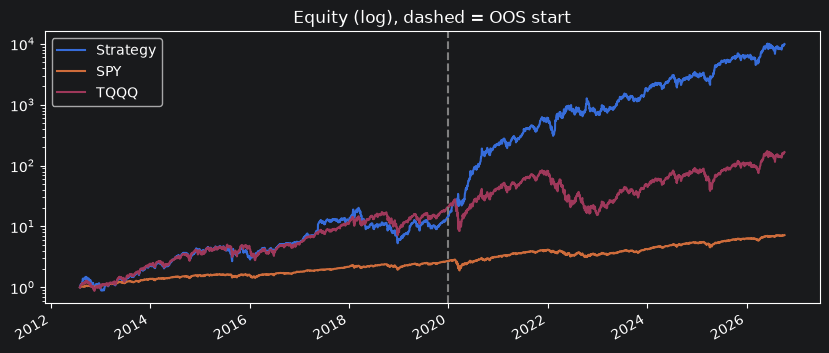


==================== is_grid ====================
== 追踪止损 （行=止损，列=止盈）
IS Sharpe


tp,NaN,0.15,0.25,0.40
sl,,,,
NaN,0.99,0.99,1.08,1.04
0.06,0.71,0.72,0.78,0.80
0.08,0.56,0.62,0.64,0.65
0.10,0.55,0.63,0.64,0.64
0.12,0.65,0.78,0.75,0.73


IS MDD


tp,NaN,0.15,0.25,0.40
sl,,,,
NaN,-0.74,-0.64,-0.63,-0.74
0.06,-0.49,-0.42,-0.46,-0.49
0.08,-0.56,-0.50,-0.54,-0.56
0.10,-0.59,-0.53,-0.58,-0.59
0.12,-0.64,-0.57,-0.62,-0.64


== 固定止损 （行=止损，列=止盈）
IS Sharpe


...


==================== live_oct ====================
窗口未完成：计划结束 2026-10-24，当前数据截至 2026-10-07。
用 2026-09-30 及以前的数据选参（冻结）: 固定 止损=0.12 止盈=0.15 | 数据最后一天: 2026-10-07


,方案,区间,交易日,累计收益,最大回撤
0,基线（无止损止盈）,2026-10-01~2026-10-07,5,+5.96%,-0.75%
1,选中参数,2026-10-01~2026-10-07,5,+5.96%,-0.75%
2,买入持有 SPY,2026-10-01~2026-10-07,5,+1.91%,-0.24%
3,买入持有 TQQQ,2026-10-01~2026-10-07,5,+7.16%,-0.75%


信号（每日收盘时的目标持仓）:


,2026-09-30,2026-10-01,2026-10-02,2026-10-05,2026-10-06,2026-10-07
target,TQQQ,TQQQ,TQQQ,TQQQ,TQQQ,TQQQ


,基线（无止损止盈）,选中参数
2026-09-30,1.0000,1.0000
2026-10-01,0.9976,0.9976
2026-10-02,1.0265,1.0265
2026-10-05,1.0532,1.0532
2026-10-06,1.0675,1.0675
2026-10-07,1.0596,1.0596


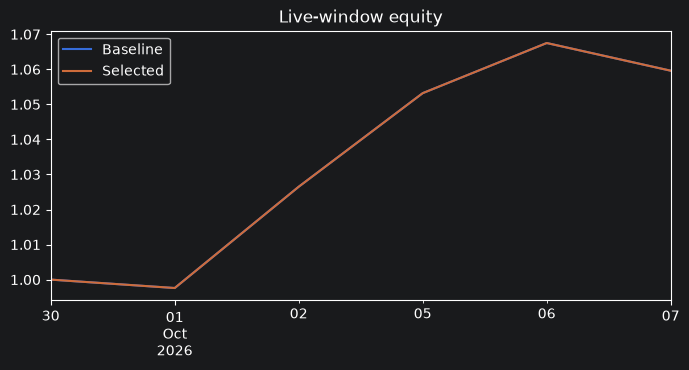


Pipeline 运行完成。结果保存在 results 字典。


In [3]:
# ===== 只需修改这里的配置，然后点击 Run All =====
CSV_PATH = None                # 自动寻找 ../data/raw/etf_daily.csv；也可填绝对路径
STAGES_TO_RUN = None            # None = 全部；例如 ['baseline', 'is_grid']
LIVE_START = '2026-10-01'
LIVE_END = '2026-10-24'

results = main(
    csv_path=CSV_PATH,
    stages=STAGES_TO_RUN,
    live_start=LIVE_START,
    live_end=LIVE_END,
)
